In [1]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from stl import mesh
import pyvista as pv

from tqdm import tqdm

# for the maximum spanning tree clearance method
from iterative_section_minimiser import mesh_intersect
from geometry import to2D, describe

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Read the conduit mapping. 

In [3]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [4]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [5]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]
section_node_kwargs = p["section_node_kwargs"]

In [ ]:
# try here some heuristic for a conduit, a centreline and some vectors. 

def describe_heuristics(conduit, ct_list, k =1):
    ct, P1, P2, ct_vecs = ct_list[conduit-1]
    themesh = list_meshes[conduit-1]
    n = len(ct)
    thesections = np.arange(0, n)

    sections2d = []

    for thesection in tqdm(thesections[::k], total=int(n/k)):
        if (np.linalg.norm(ct_vecs[thesection]) -1)**2 < 1e-6 :
            intersect = mesh_intersect(themesh, ct[thesection], ct_vecs[thesection])
            if intersect is not None:
                polyline3d = intersect[0]
                section2d, _, _ = to2D(polyline3d, ct_vecs[thesection], returnTransform=True, verbose=False)
                sections2d.append(section2d)
        
    areas = []
    aspect_ratios = []
    dhs = []

    tortuosity = np.sum(np.linalg.norm(ct[1:]-ct[:-1], axis =1)) / np.linalg.norm(P2-P1)


    for section2d in sections2d:
        try:
            description = describe(section2d)
            areas.append(description["area"])
            dhs.append(description["hydraulic_diameter"])
            aspect_ratios.append(description["ellipse_aspect_ratio"])
            
        except ValueError:
            print("invalid section")   
    
    return areas, np.mean(areas), aspect_ratios, np.mean(aspect_ratios), dhs, np.mean(dhs), tortuosity

We load all the meshes in memory

In [7]:
# list all meshes. 
list_meshes = []
list_meshes_fp = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"../data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))
    list_meshes_fp.append(mesh_fp)

In [8]:
# list all lbc centrelines, the sources and the target points
# work out all the looking vectors
# store the sections in a sections2d folder.

list_lbc_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    lbc_ct_fp = f"../temp/{conduit_id}_{conduit_name}/lbc/{conduit_name}_centreline.txt"
    # load the centreline
    lbc_ct = np.loadtxt(lbc_ct_fp)
    lbc_ct_inner_vecs = lbc_ct[2:] - lbc_ct[:-2]
    vec_start = lbc_ct[1] - lbc_ct[0]
    vec_end = lbc_ct[-1] - lbc_ct[-2]
    # concatenate the vectors
    lbc_ct_vecs = np.vstack([[vec_start], lbc_ct_inner_vecs, [vec_end]])
    # normalise them
    lbc_ct_vecs /= np.expand_dims(np.linalg.norm(lbc_ct_vecs, axis =1), axis =-1)
    
    P1 = lbc_ct[0]
    P2 = lbc_ct[-1]

    list_lbc_ct.append((lbc_ct, P1, P2, lbc_ct_vecs))

Theoretical heuristics: made from ideal centrelines, resampled at 100 points.

In [10]:
list_theory_ct = []

N = 250

ct1237 = np.vstack([np.linspace(-4.95, 4.95, N), np.zeros(N), np.zeros(N)]).T
ct4 = np.vstack([np.linspace(-3.79, 3.79, N), np.zeros(N), np.zeros(N)]).T
thetai = np.linspace(-np.pi, -np.pi/N, int(N/2))*0.99
thetaib = np.linspace(-(N-1)/N*np.pi, 0, int(N/2))*0.99

ct5a = np.vstack([np.cos(thetai)*2.5 -2.5, np.sin(thetai)*2.5, np.zeros(int(N/2))]).T
ct5b = np.vstack([np.cos(thetaib)*2.5 +2.5, -np.sin(thetaib)*2.5, np.zeros(int(N/2))]).T
ct5 = np.vstack([ct5a, ct5b])
ct6 = ct5.copy()
ct6[:, 1] *=2

ct1237_vec = np.zeros((N,3))
ct1237_vec[:, 0] = 1
ct4_vec = np.zeros((N,3))
ct4_vec[:, 0] = 1

ct5_vec = np.zeros((N, 3))
ct5_vec[:int(N/2), 0] = -np.sin(thetai) 
ct5_vec[int(N/2):, 0] = -np.sin(thetaib)
ct5_vec[:int(N/2), 1] = np.cos(thetai)
ct5_vec[int(N/2):, 1] = -np.cos(thetaib)

ct5_vec /= np.expand_dims(np.linalg.norm(ct5_vec, axis =1), -1)

ct6_vec = np.zeros((N, 3))
ct6_vec[:int(N/2), 0] = -np.sin(thetai) 
ct6_vec[int(N/2):, 0] = -np.sin(thetaib)
ct6_vec[:int(N/2), 1] = 2*np.cos(thetai)
ct6_vec[int(N/2):, 1] = -2*np.cos(thetaib)

ct6_vec /= np.expand_dims(np.linalg.norm(ct6_vec, axis =1), -1)



list_theory_ct.append([ct1237, ct1237[0], ct1237[-1],ct1237_vec])
list_theory_ct.append([ct1237, ct1237[0], ct1237[-1],ct1237_vec])
list_theory_ct.append([ct1237, ct1237[0], ct1237[-1],ct1237_vec])
list_theory_ct.append([ct4, ct4[0], ct4[-1],ct4_vec])
list_theory_ct.append([ct5, ct5[0], ct5[-1],ct5_vec])
list_theory_ct.append([ct6, ct6[0], ct6[-1],ct6_vec])
list_theory_ct.append([ct1237, ct1237[0], ct1237[-1],ct1237_vec])


In [11]:
# list all mst centrelines, the sources and the target points
# work out all the looking vectors

list_mst_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    if k < 7:
        delta = 200
    else:
        delta = 400
        
    mst_ct_fp = f"../temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-direct.txt"
    # load the centreline
    mst_ct = np.loadtxt(mst_ct_fp)
    mst_ct_inner_vecs = mst_ct[2:] - mst_ct[:-2]
    vec_start = mst_ct[1] - mst_ct[0]
    vec_end = mst_ct[-1] - mst_ct[-2]
    # concatenate the vectors
    mst_ct_vecs = np.vstack([[vec_start], mst_ct_inner_vecs, [vec_end]])
    # normalise them
    mst_ct_vecs /= np.expand_dims(np.linalg.norm(mst_ct_vecs, axis =1), axis =-1)
    
    P1 = mst_ct[0]
    P2 = mst_ct[-1]

    list_mst_ct.append((mst_ct, P1, P2, mst_ct_vecs))

In [12]:
# list all iterative centrelines, the sources and the target points
list_iter_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    iter_ct_fp = f"../temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_centreline.txt"
    iter_norm_fp = f"../temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_vectors.txt"

    iter_ct = np.loadtxt(iter_ct_fp)
    iter_norm = np.loadtxt(iter_norm_fp)
    print(iter_ct_fp)
    print(np.mean(iter_ct, axis = 0)) 
    P1 = iter_ct[0]
    P2 = iter_ct[-1]

    list_iter_ct.append((iter_ct[:-1], P1, P2, iter_norm))

../temp/1_straight_cyl/iterative/straight_cyl_centreline.txt
[-1.05062572e-01  9.81152589e-05  1.37409231e-04]
../temp/2_straight_elp/iterative/straight_elp_centreline.txt
[-1.06589522e-01  2.39166368e-04  8.27264029e-05]
../temp/3_wavy/iterative/wavy_centreline.txt
[ 0.00551136 -0.00030335  0.00060712]
../temp/4_rough/iterative/rough_centreline.txt
[-0.12904862 -0.02858769 -0.03483494]
../temp/5_sinu_1/iterative/sinu_1_centreline.txt
[0.01606131 0.01713299 0.00169107]
../temp/6_sinu_2/iterative/sinu_2_centreline.txt
[-4.42635527e+00  2.01393364e+00 -1.96948762e-03]
../temp/7_branching/iterative/branching_centreline.txt
[0.0363256  0.01212195 0.00609678]
../temp/8_archamps/iterative/archamps_centreline.txt
[-0.06430868  0.22111751 -1.00721533]
../temp/9_motiers/iterative/motiers_centreline.txt
[ 0.80790049 -0.63976681 -0.39329461]
../temp/10_faux_monnayeurs/iterative/faux_monnayeurs_centreline.txt
[ 0.34112024 -0.03008052 -1.64151216]


We keep the previously computed values. 

In [13]:
keep = False

In [ ]:

if keep == False:
    theory_conduit_heuristics = []
    theory_conduit_descriptors = []

    for conduit in range(1,8):
        a, amean, r, rmean, d, dmean, tort = describe_heuristics(conduit, list_theory_ct)
        theory_conduit_heuristics.append([conduit, amean, rmean, dmean, tort])
        theory_conduit_descriptors.append([np.ones(len(a))*conduit, a, r, d])

    theory_conduit_heuristics = np.array(theory_conduit_heuristics)

    np.savetxt("../temp/theory_heuristics.txt", 
            theory_conduit_heuristics, 
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity", 
            delimiter=",")

    np.savetxt("../temp/theory_descriptors.txt", 
            np.vstack([np.array(elem).T for elem in theory_conduit_descriptors]), 
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity",
            delimiter =",")
else:
    theory_conduit_heuristics = np.loadtxt("../temp/theory_heuristics.txt", skiprows=1, delimiter=",")
    theory_conduit_descriptors = np.loadtxt("../temp/theory_descriptors.txt", skiprows=1, delimiter=",")



 77%|███████▋  | 192/250 [01:02<00:17,  3.23it/s]

In [ ]:
keep = True

In [ ]:
if keep == False:
    lbc_conduit_heuristics = []
    lbc_conduit_descriptors = []

    for conduit in range(1,8):
        a, amean, r, rmean, d, dmean, tort = describe_heuristics(conduit, list_lbc_ct)
        lbc_conduit_heuristics.append([conduit, amean, rmean, dmean, tort])
        lbc_conduit_descriptors.append([np.ones(len(a))*conduit, a, r, d])

    lbc_conduit_heuristics = np.array(lbc_conduit_heuristics)

    np.savetxt("../temp/lbc_heuristics.txt", 
            lbc_conduit_heuristics,
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity", 
            delimiter=",")

    np.savetxt("../temp/lbc_descriptors.txt", 
            np.vstack([np.array(elem).T for elem in lbc_conduit_descriptors]), 
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity",
            delimiter =",")
    
else:
    lbc_conduit_heuristics = np.loadtxt("../temp/lbc_heuristics.txt", skiprows=1, delimiter=",")
    lbc_conduit_descriptors = np.loadtxt("../temp/lbc_descriptors.txt", skiprows=1, delimiter=",")


In [ ]:
if keep == False:

    mst_conduit_heuristics = []
    mst_conduit_descriptors = []

    for conduit in range(1,8):
        a, amean, r, rmean, d, dmean, tort = describe_heuristics(conduit, list_mst_ct)
        mst_conduit_heuristics.append([conduit, amean, rmean, dmean, tort])
        mst_conduit_descriptors.append([np.ones(len(a))*conduit, a, r, d])


    mst_conduit_heuristics = np.array(mst_conduit_heuristics)

    np.savetxt("../temp/mst_heuristics.txt", 
            mst_conduit_heuristics, 
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity", 
            delimiter=",")

    np.savetxt("../temp/mst_descriptors.txt", 
            np.vstack([np.array(elem).T for elem in mst_conduit_descriptors]),
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity",
                delimiter =",")

else:
    mst_conduit_heuristics = np.loadtxt("../temp/mst_heuristics.txt", skiprows=1, delimiter=",")
    mst_conduit_descriptors = np.loadtxt("../temp/mst_descriptors.txt", skiprows=1, delimiter=",")


In [ ]:
if keep == False:
    iter_conduit_heuristics = []
    iter_conduit_descriptors = []

    for conduit in range(1,8):
        a, amean, r, rmean, d, dmean, tort = describe_heuristics(conduit, list_iter_ct)
        iter_conduit_heuristics.append([conduit, amean, rmean, dmean, tort])
        iter_conduit_descriptors.append([np.ones(len(a))*conduit, a, r, d])

    iter_conduit_heuristics = np.array(iter_conduit_heuristics)

    np.savetxt("../temp/iter_heuristics.txt", 
            iter_conduit_heuristics, 
            header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity", 
            delimiter=",")

    np.savetxt("../temp/iter_descriptors.txt", np.vstack([np.array(elem).T for elem in iter_conduit_descriptors]),
           header="ID,mean cross section, mean aspect ratio, mean hydraulic diameter, tortuosity",
           delimiter =",")
    
else:
    iter_conduit_heuristics = np.loadtxt("../temp/iter_heuristics.txt", skiprows=1, delimiter=",")
    iter_conduit_descriptors = np.loadtxt("../temp/iter_descriptors.txt", skiprows=1, delimiter=",")


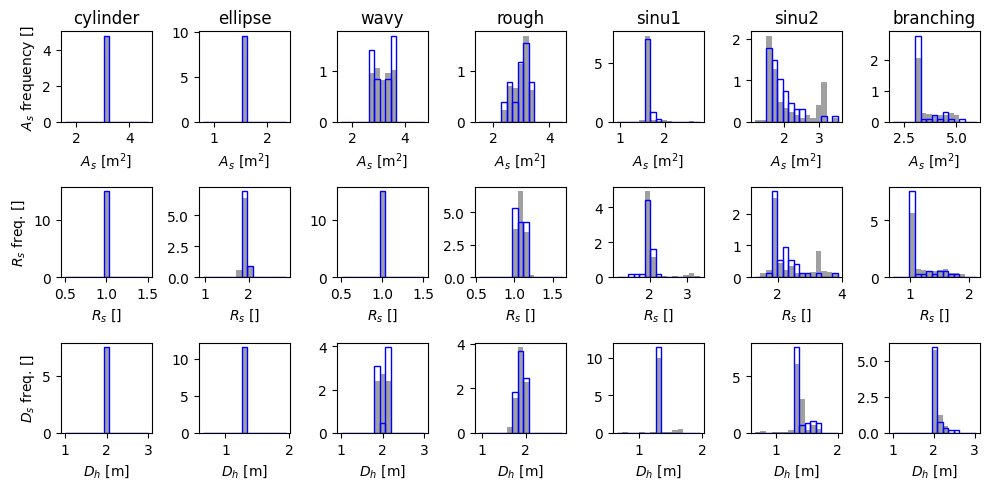

In [ ]:
fig, axes = plt.subplots(3, 7, figsize = (10, 5))
xlabels = ["$A_s$ [m$^2$]", "$R_s$ []", "$D_h$ [m]"]

for j, row in enumerate(axes):
    for i, ax in enumerate(row):
        lowxlim = 0.5 * np.mean(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1])
        highxlim = 1.5 * np.mean(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1])

        ax.hist(lbc_conduit_descriptors[lbc_conduit_descriptors[:, 0]==i+1][:, j+1], 
                bins = np.linspace(lowxlim, highxlim, 16), 
                density = True, label ="LBC", edgecolor = "blue", facecolor="None")
        ax.hist(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1][:, j+1], 
                bins = np.linspace(lowxlim, highxlim, 16),
                facecolor="grey", 
                alpha = 0.75, 
                density=True, label="benchmark", zorder=-10)
        ax.set_xlabel(xlabels[j])
        

titles = ["cylinder", "ellipse", "wavy", "rough", "sinu1", "sinu2", "branching"]
for ax, title in zip(axes[0], titles):
    ax.set_title(title)

ylabels = ["frequency []"]*3

for ax, ylabel in zip(axes[:,0], ylabels):
    ax.set_ylabel(ylabel)


#axes[0,0].legend()
plt.tight_layout()
plt.savefig("../temp/LBC_vs_benchmark_distributions_heuristics.png", dpi = 300)


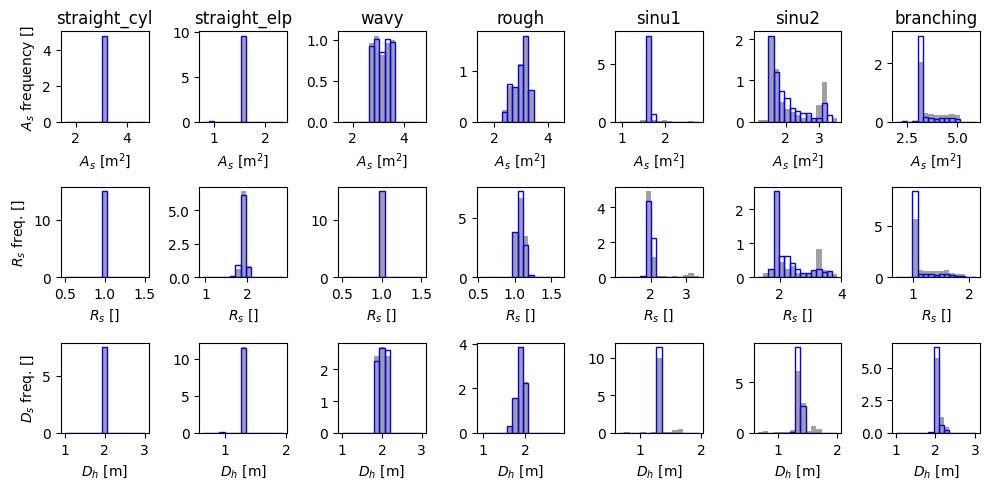

In [204]:
fig, axes = plt.subplots(3, 7, figsize = (10, 5))
xlabels = ["$A_s$ [m$^2$]", "$R_s$ []", "$D_h$ [m]"]

for j, row in enumerate(axes):
    for i, ax in enumerate(row):
        lowxlim = 0.5 * np.mean(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1])
        highxlim = 1.5 * np.mean(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1])

        ax.hist(mst_conduit_descriptors[mst_conduit_descriptors[:, 0]==i+1][:, j+1], 
                bins = np.linspace(lowxlim, highxlim, 16), 
                density = True, label ="mst", edgecolor = "blue", facecolor="None")
        ax.hist(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1][:, j+1], 
                bins = np.linspace(lowxlim, highxlim, 16),
                facecolor="grey", 
                alpha = 0.75, 
                density=True, label="benchmark", zorder=-10)
        ax.set_xlabel(xlabels[j])
        

titles = ["straight_cyl", "straight_elp", "wavy", "rough", "sinu1", "sinu2", "branching"]
for ax, title in zip(axes[0], titles):
    ax.set_title(title)

ylabels = ["$A_s$ frequency []", "$R_s$ freq. []", "$D_s$ freq. []"]
for ax, ylabel in zip(axes[:,0], ylabels):
    ax.set_ylabel(ylabel)


plt.tight_layout()
plt.savefig("../temp/MST_vs_benchmark_distributions_heuristics.png", dpi = 300)


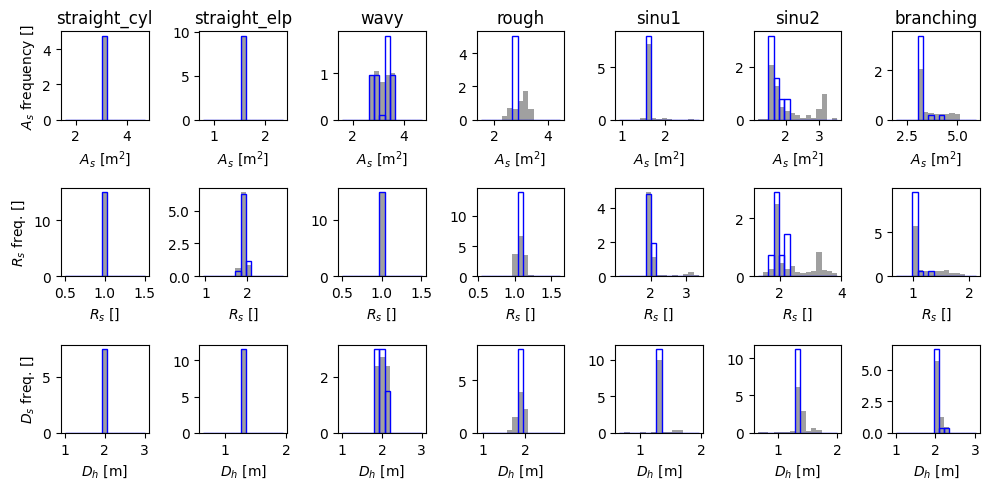

In [203]:
fig, axes = plt.subplots(3, 7, figsize = (10, 5))
xlabels = ["$A_s$ [m$^2$]", "$R_s$ []", "$D_h$ [m]"]

for j, row in enumerate(axes):
    for i, ax in enumerate(row):
        lowxlim = 0.5 * np.mean(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1])
        highxlim = 1.5 * np.mean(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1])

        ax.hist(iter_conduit_descriptors[iter_conduit_descriptors[:, 0]==i+1][:, j+1], 
                bins = np.linspace(lowxlim, highxlim, 16), 
                density = True, label ="iterative", edgecolor = "blue", facecolor="None")
        ax.hist(theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1][:, j+1], 
                bins = np.linspace(lowxlim, highxlim, 16),
                facecolor="grey", 
                alpha = 0.75, 
                density=True, label="benchmark", zorder=-10)
        ax.set_xlabel(xlabels[j])
        

titles = ["straight_cyl", "straight_elp", "wavy", "rough", "sinu1", "sinu2", "branching"]
for ax, title in zip(axes[0], titles):
    ax.set_title(title)

ylabels = ["$A_s$ frequency []", "$R_s$ freq. []", "$D_s$ freq. []"]
for ax, ylabel in zip(axes[:,0], ylabels):
    ax.set_ylabel(ylabel)


plt.tight_layout()
plt.savefig("../temp/Iterative_vs_benchmark_distributions_heuristics.png", dpi = 300)


In [140]:
from scipy.stats import wasserstein_distance

In [147]:
w1_dist_lbc = np.zeros((3, 7))

for j, row in enumerate(w1_dist_lbc):
    for i, _ in enumerate(row):
        theory = theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1]
        lbc = lbc_conduit_descriptors[lbc_conduit_descriptors[:, 0]==i+1, j+1]
        w1_dist_lbc[j,i] = wasserstein_distance(theory, lbc)

       


In [149]:
w1_dist_mst = np.zeros((3, 7))

for j, row in enumerate(w1_dist_mst):
    for i, _ in enumerate(row):
        theory = theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1]
        mst = mst_conduit_descriptors[mst_conduit_descriptors[:, 0]==i+1, j+1]
        w1_dist_mst[j,i] = wasserstein_distance(theory, mst)

       

In [150]:
w1_dist_iter = np.zeros((3, 7))

for j, row in enumerate(w1_dist_iter):
    for i, _ in enumerate(row):
        theory = theory_conduit_descriptors[theory_conduit_descriptors[:, 0]==i+1, j+1]
        iter = iter_conduit_descriptors[iter_conduit_descriptors[:, 0]==i+1, j+1]
        w1_dist_iter[j,i] = wasserstein_distance(theory, iter)

       

In [156]:
from matplotlib.gridspec import GridSpec

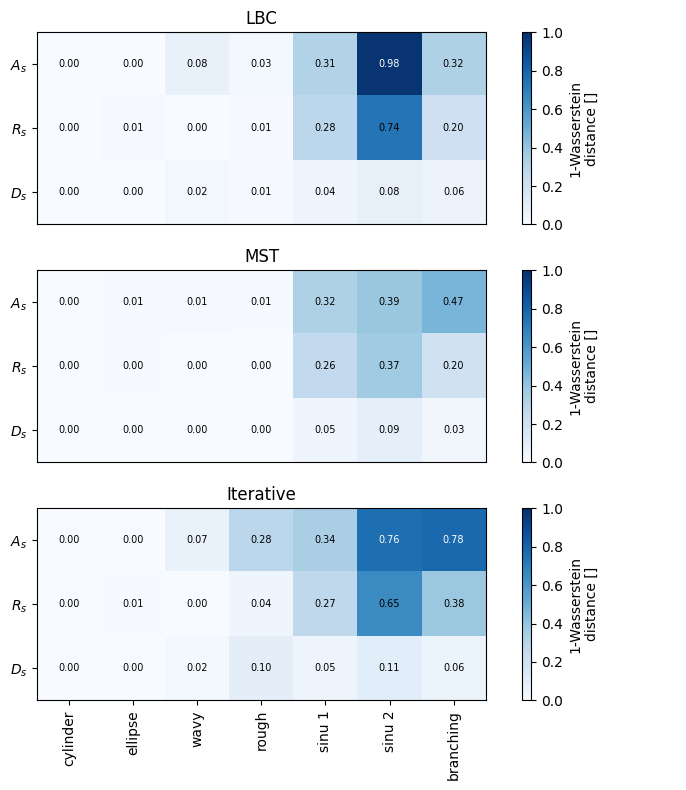

In [199]:
fig = plt.figure(figsize = (8, 8))

gs = GridSpec(nrows=3, ncols=17)
ax3 = fig.add_subplot(gs[2:,:16])
ax1 = fig.add_subplot(gs[:1,:16])
im1 = ax1.imshow(w1_dist_lbc, vmin = 0, vmax = 1, cmap ="Blues")

ax2 = fig.add_subplot(gs[1:2,:16])
im2 = ax2.imshow(w1_dist_mst, vmin = 0, vmax=1, cmap ="Blues")

im3 = ax3.imshow(w1_dist_iter, vmin = 0, vmax=1, cmap ="Blues")

axcolorbar = fig.add_subplot(gs[:1, 16:])

for spine in ["top", "bottom", "right", "left"]:
    axcolorbar.spines[spine].set_visible(False)
axcolorbar.set_xticks([])
axcolorbar.set_yticks([])

titles  = ("LBC", "MST", "Iterative")
axes = (ax1, ax2, ax3)
dist_matrices = (w1_dist_lbc, w1_dist_mst, w1_dist_iter)
ylabels = ("$A_s$", "$R_s$", "$D_s$")

for im, title, ax, distmatrix in zip((im1, im2, im3), titles, axes, dist_matrices): 
    cax =plt.colorbar(im)
    cax.set_label("1-Wasserstein\ndistance []")
    ax.set_title(title)
    ax.set_yticks([0,1,2])
    ax.set_yticklabels(ylabels)
    for j, row in enumerate(distmatrix):
        for i, elem in enumerate(row):
            if elem > 0.75:
                ax.text(i, j, f"{elem:.2f}", fontsize=7, color = "white", va="center", ha="center")
            else: 
                ax.text(i, j, f"{elem:.2f}", fontsize=7, color = "black", va="center", ha="center")

xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "branching"]
ax3.set_xticks([0,1,2,3,4,5,6])
ax3.set_xticklabels(xlabels, rotation=90)
ax1.set_xticks([])
ax2.set_xticks([])
plt.tight_layout()
plt.savefig("../temp/1-wasserstein-distances.png", dpi = 300)